In [1]:
   %pip install pandas matplotlib seaborn scikit-learn
   

Note: you may need to restart the kernel to use updated packages.


Merged shape: (113425, 25)

===== BUSINESS KPIs =====
Total Orders: 99441
Unique Customers: 96096
Total Revenue (BRL): 16008872.12
Avg Order Value (BRL): 160.99
Avg Review Score: 4.07
Late Delivery %: 7.91
Avg Delivery Days: 12.0
Repeat Customers %: 3.12

===== SQL: Top 10 Categories by Revenue =====
                category     revenue  orders
0          health_beauty  1233131.72    8647
1          watches_gifts  1166176.98    5495
2         bed_bath_table  1023434.76    9272
3         sports_leisure   954852.55    7530
4  computers_accessories   888724.61    6530
5        furniture_decor   711927.69    6307
6             housewares   615628.69    5743
7             cool_stuff   610204.10    3559
8                   auto   578966.65    3810
9                   toys   471286.48    3804


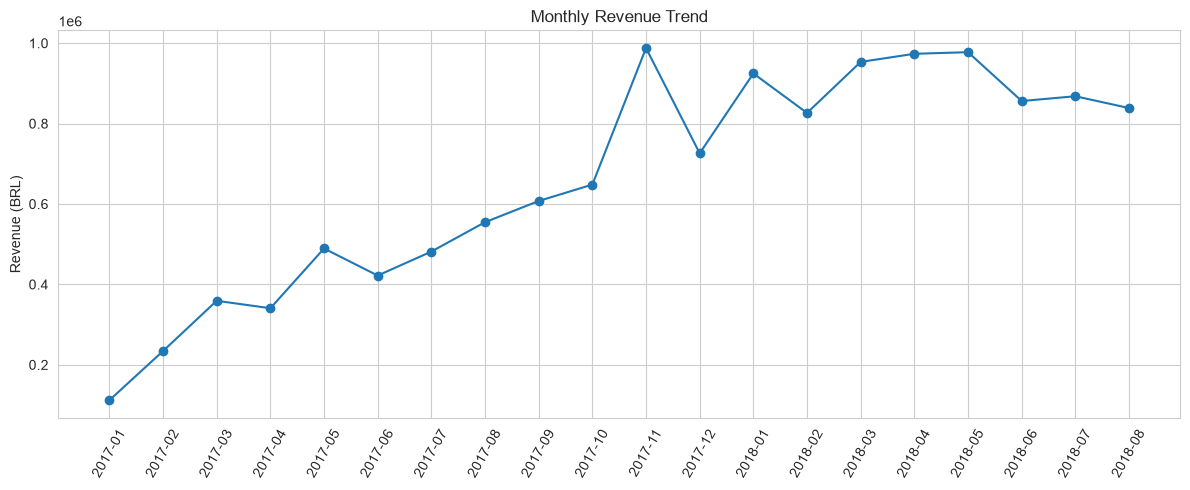

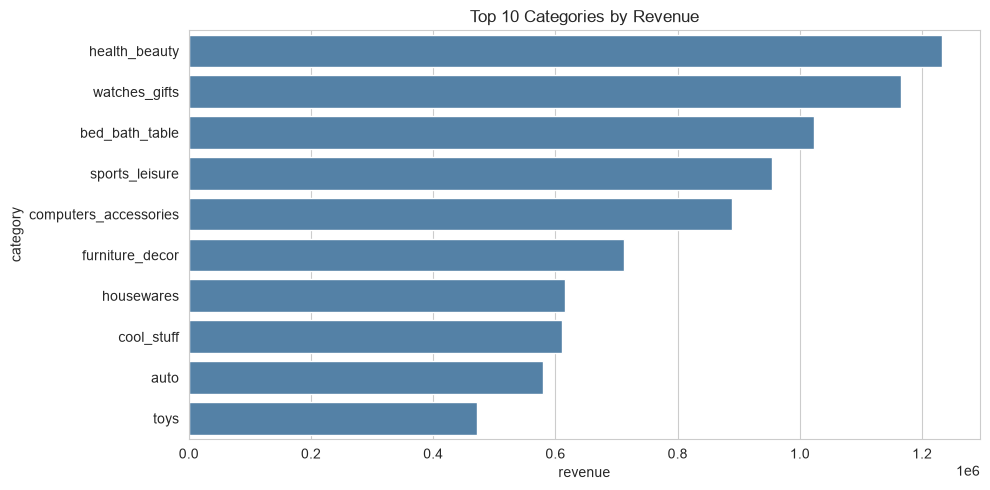

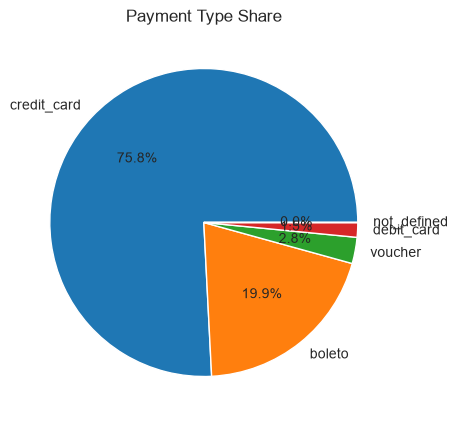

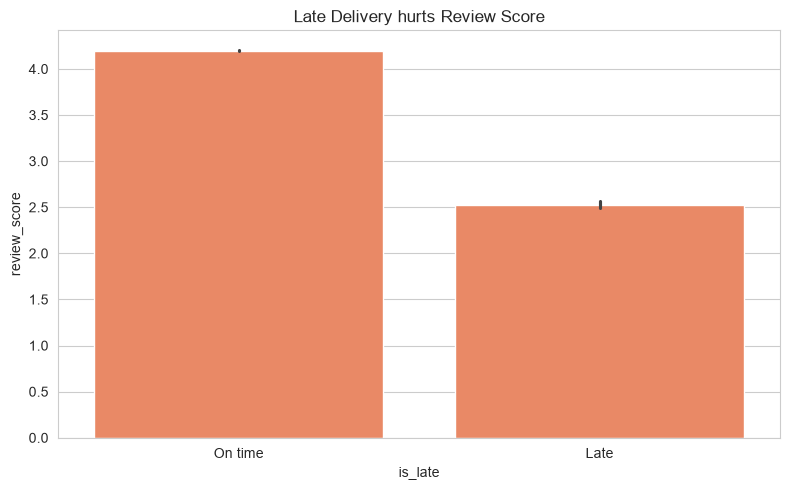


===== ML MODEL: Late Delivery Prediction =====
Accuracy: 0.727
ROC-AUC: 0.731
              precision    recall  f1-score   support

           0       0.96      0.74      0.83     20296
           1       0.16      0.60      0.26      1742

    accuracy                           0.73     22038
   macro avg       0.56      0.67      0.54     22038
weighted avg       0.89      0.73      0.79     22038



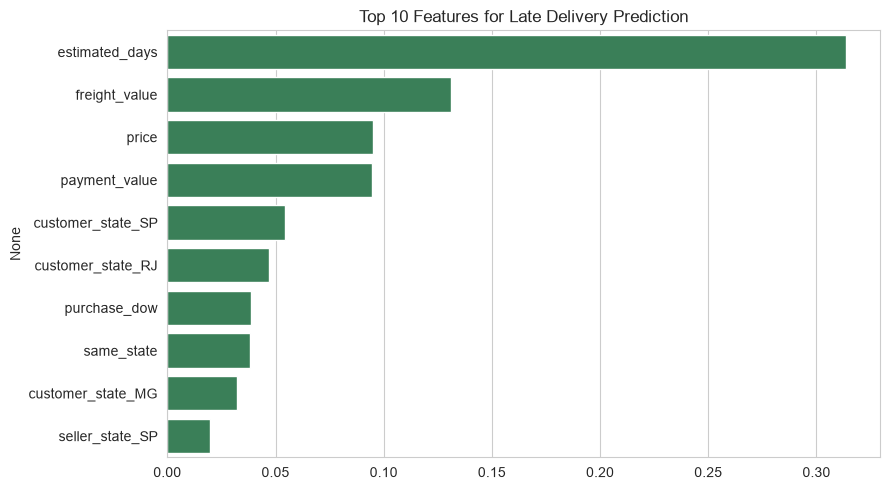


Saved: ../data/cleaned_for_powerbi.csv (99441, 15)
Charts saved in ../images/


In [1]:
import pandas as pd, numpy as np, sqlite3, os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

sns.set_style("whitegrid")
os.makedirs("../images", exist_ok=True)

# ---------- 1. LOAD ----------
customers = pd.read_csv("../data/olist_customers_dataset.csv")
order_items = pd.read_csv("../data/olist_order_items_dataset.csv")
payments = pd.read_csv("../data/olist_order_payments_dataset.csv")
reviews = pd.read_csv("../data/olist_order_reviews_dataset.csv")
orders = pd.read_csv("../data/olist_orders_dataset.csv")
products = pd.read_csv("../data/olist_products_dataset.csv")
sellers = pd.read_csv("../data/olist_sellers_dataset.csv")
category_translation = pd.read_csv("../data/product_category_name_translation.csv")

# ---------- 2. MERGE ----------
pay = payments.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    payment_type=("payment_type", "first")).reset_index()
rev = reviews.groupby("order_id").agg(review_score=("review_score", "mean")).reset_index()
products = products.merge(category_translation, on="product_category_name", how="left")

df = orders.merge(customers, on="customer_id", how="left")
df = df.merge(order_items, on="order_id", how="left")
df = df.merge(products[["product_id", "product_category_name_english"]], on="product_id", how="left")
df = df.merge(sellers, on="seller_id", how="left")
df = df.merge(pay, on="order_id", how="left")
df = df.merge(rev, on="order_id", how="left")
print("Merged shape:", df.shape)

# ---------- 3. CLEANING & FEATURE ENGINEERING ----------
date_cols = ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    df[c] = pd.to_datetime(df[c])

df["product_category_name_english"] = df["product_category_name_english"].fillna("unknown")
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["purchase_dow"] = df["order_purchase_timestamp"].dt.dayofweek
df["delivery_days"] = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.days
df["estimated_days"] = (df["order_estimated_delivery_date"] - df["order_purchase_timestamp"]).dt.days
df["is_late"] = (df["order_delivered_customer_date"] > df["order_estimated_delivery_date"]).astype(int)
df["same_state"] = (df["customer_state"] == df["seller_state"]).astype(int)

# ---------- 4. KPIs ----------
delivered = df[df["order_status"] == "delivered"].copy()
revenue_df = df.drop_duplicates("order_id")
kpi = {
    "Total Orders": df["order_id"].nunique(),
    "Unique Customers": df["customer_unique_id"].nunique(),
    "Total Revenue (BRL)": round(revenue_df["payment_value"].sum(), 2),
    "Avg Order Value (BRL)": round(revenue_df["payment_value"].mean(), 2),
    "Avg Review Score": round(revenue_df["review_score"].mean(), 2),
    "Late Delivery %": round(delivered["is_late"].mean() * 100, 2),
    "Avg Delivery Days": round(delivered["delivery_days"].mean(), 1),
}
print("\n===== BUSINESS KPIs =====")
for k, v in kpi.items():
    print(f"{k}: {v}")

orders_per_cust = df.groupby("customer_unique_id")["order_id"].nunique()
print(f"Repeat Customers %: {round((orders_per_cust > 1).mean() * 100, 2)}")

# ---------- 5. SQL (sqlite) ----------
conn = sqlite3.connect(":memory:")
df.assign(order_purchase_timestamp=df["order_purchase_timestamp"].astype(str),
          order_delivered_customer_date=df["order_delivered_customer_date"].astype(str),
          order_estimated_delivery_date=df["order_estimated_delivery_date"].astype(str)
          ).to_sql("sales", conn, index=False)

q1 = """
SELECT product_category_name_english AS category,
       ROUND(SUM(price), 2) AS revenue,
       COUNT(DISTINCT order_id) AS orders
FROM sales
WHERE order_status = 'delivered'
GROUP BY category
ORDER BY revenue DESC
LIMIT 10;
"""
top_cat = pd.read_sql(q1, conn)
print("\n===== SQL: Top 10 Categories by Revenue =====")
print(top_cat)

q2 = """
SELECT purchase_month, ROUND(SUM(price), 2) AS revenue, COUNT(DISTINCT order_id) AS orders
FROM sales
WHERE order_status = 'delivered'
GROUP BY purchase_month
ORDER BY purchase_month;
"""
monthly = pd.read_sql(q2, conn)
monthly = monthly[(monthly["purchase_month"] >= "2017-01") & (monthly["purchase_month"] <= "2018-08")]

# ---------- 6. CHARTS ----------
plt.figure(figsize=(12, 5))
plt.plot(monthly["purchase_month"], monthly["revenue"], marker="o")
plt.xticks(rotation=60); plt.title("Monthly Revenue Trend"); plt.ylabel("Revenue (BRL)")
plt.tight_layout(); plt.savefig("../images/1_monthly_revenue.png"); plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=top_cat, y="category", x="revenue", color="steelblue")
plt.title("Top 10 Categories by Revenue"); plt.tight_layout()
plt.savefig("../images/2_top_categories.png"); plt.show()

plt.figure(figsize=(7, 5))
revenue_df["payment_type"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Payment Type Share"); plt.ylabel("")
plt.savefig("../images/3_payment_types.png"); plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=delivered.assign(is_late=delivered["is_late"].map({0: "On time", 1: "Late"})),
            x="is_late", y="review_score", color="coral")
plt.title("Late Delivery hurts Review Score"); plt.tight_layout()
plt.savefig("../images/4_late_vs_review.png"); plt.show()

# ---------- 7. MACHINE LEARNING: predict late delivery ----------
ml = delivered.dropna(subset=["delivery_days", "price", "freight_value", "payment_value",
                              "customer_state", "seller_state"]).copy()
features = ["price", "freight_value", "payment_value", "estimated_days",
            "purchase_dow", "same_state", "customer_state", "seller_state"]
X = pd.get_dummies(ml[features], columns=["customer_state", "seller_state"], drop_first=True)
y = ml["is_late"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=100, max_depth=12, class_weight="balanced",
                               random_state=42, n_jobs=-1)
model.fit(X_tr, y_tr)
pred = model.predict(X_te)
print("\n===== ML MODEL: Late Delivery Prediction =====")
print("Accuracy:", round(accuracy_score(y_te, pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_te, model.predict_proba(X_te)[:, 1]), 3))
print(classification_report(y_te, pred))

imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=imp.values, y=imp.index, color="seagreen")
plt.title("Top 10 Features for Late Delivery Prediction"); plt.tight_layout()
plt.savefig("../images/5_feature_importance.png"); plt.show()

# ---------- 8. EXPORT for Power BI ----------
final = df.drop_duplicates("order_id")[[
    "order_id", "customer_unique_id", "customer_state", "seller_state", "order_status",
    "purchase_month", "product_category_name_english", "price", "freight_value",
    "payment_value", "payment_type", "review_score", "delivery_days", "estimated_days", "is_late"]]
final.to_csv("../data/cleaned_for_powerbi.csv", index=False)
print("\nSaved: ../data/cleaned_for_powerbi.csv", final.shape)
print("Charts saved in ../images/")

In [2]:
import os
print("Code is running from:", os.getcwd())
print("Files in this folder:", os.listdir("."))

Code is running from: d:\Cognevance Internship\Task\TASK 3
Files in this folder: ['01_analysis_and_model.ipynb', 'Data', 'Notebook']
